# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Data Processing and Linear Regression Exploration
*By Mark Lambert - C00192497*

---

In third year I built and deployed a LastFm scrobbling program, which familiarised me with the LastFM API. 

I decided for my Data Science & Machine Learning Portfolio that usming this data would be interesting and applicable.
        
The first step is to connect with the API using an API key, and then pull all of the scrobbles using the ```User.getRecentTracks``` header.

```%pip install pandas scikit-learn matplotlib```

In [1]:
%pip install pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

API_KEY = ' api key'
USERNAME = ' username'

all_tracks = []
page = 1
total_pages = 1

while page <= total_pages:
    response = requests.get('http://ws.audioscrobbler.com/2.0/', params={
        'method': 'user.getrecenttracks',
        'user': USERNAME,
        'api_key': API_KEY,
        'format': 'json',
        'limit': 200,
        'page': page
    })
    data = response.json()
    if page == 1:
        total_pages = int(data['recenttracks']['@attr']['totalPages'])
    all_tracks.extend(data['recenttracks']['track'])
    page += 1

The data's raw columns.

The ones that this portfolio will focus on are **artist, album, name and date**. ```@attr``` holds songs that are marked ```nowplaying = true```. 

As such, anything with this attribute will also be ignored later on.

In [3]:
scrobblesResponse = pd.DataFrame(all_tracks)

scrobblesResponse.columns

Index(['artist', 'streamable', 'image', 'mbid', 'album', 'name', '@attr',
       'url', 'date'],
      dtype='str')

The raw data shows that the actual readable details for each artist, album are hashed, but there is an embedded ```#text``` feature within each hash which must be extracted

In [4]:
scrobblesResponse

,artist,streamable,image,mbid,album,name,@attr,url,date
0,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Glory Box,{'nowplaying': 'true'},https://www.last.fm/music/Portishead/_/Glory+Box,NaN
1,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",2d2c3253-8b61-3c02-b5e1-83be8ade482c,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Biscuit,NaN,https://www.last.fm/music/Portishead/_/Biscuit,"{'uts': '1791402595', '#text': '07 Oct 2026, 1..."
2,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",7a67d3db-6c7c-3ba9-85d1-357ddf825a7b,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Pedestal,NaN,https://www.last.fm/music/Portishead/_/Pedestal,"{'uts': '1791402292', '#text': '07 Oct 2026, 1..."
3,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",03462159-281b-47ae-9014-81c727ff557e,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Roads,NaN,https://www.last.fm/music/Portishead/_/Roads,"{'uts': '1791402072', '#text': '07 Oct 2026, 1..."
4,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",635649a0-68b4-40d1-a96d-283ed6aa1119,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Numb,NaN,https://www.last.fm/music/Portishead/_/Numb,"{'uts': '1791401768', '#text': '07 Oct 2026, 1..."
...,...,...,...,...,...,...,...,...,...
18120,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",362c85ba-c79b-478e-8321-0383c3ac8101,{'mbid': '0d2cb66c-3a32-4f81-b977-9231c461c34a...,Why Won't They Talk to Me?,NaN,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,"{'uts': '1763463648', '#text': '18 Nov 2025, 1..."
18121,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",6f93589f-4a47-4a9d-9274-09a0f437ad15,{'mbid': '10ac58ca-0655-4b16-a6cb-58fdc309de0a...,Over,NaN,https://www.last.fm/music/Portishead/_/Over,"{'uts': '1763463370', '#text': '18 Nov 2025, 1..."
18122,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",6da0b598-d9cf-4f62-8376-bc3181e509af,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Obsolete,NaN,https://www.last.fm/music/Tame+Impala/_/Obsolete,"{'uts': '1763462844', '#text': '18 Nov 2025, 1..."
18123,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,0,"[{'size': 'small', '#text': 'https://lastfm-im...",ad79b526-8df8-4e79-8756-0607df153e59,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Piece Of Heaven,NaN,https://www.last.fm/music/Tame+Impala/_/Piece+...,"{'uts': '1763462559', '#text': '18 Nov 2025, 1..."


Next, as per [Carlos Medina's article](https://medium.com/hemisferios/using-the-last-fm-api-to-extract-data-and-analyzing-it-with-python-part-1-ffe96f812455), first we must select the colums of interest and, as the column name is obscure I have chosen to rename it to **song**

In [5]:
scrobbles = scrobblesResponse

scrobbles = scrobbles[['artist', 'album', 'name', 'url', 'date']]
scrobbles.rename(columns={'name': 'song'}, inplace=True)
scrobbles

,artist,album,song,url,date
0,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Glory Box,https://www.last.fm/music/Portishead/_/Glory+Box,NaN
1,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Biscuit,https://www.last.fm/music/Portishead/_/Biscuit,"{'uts': '1791402595', '#text': '07 Oct 2026, 1..."
2,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Pedestal,https://www.last.fm/music/Portishead/_/Pedestal,"{'uts': '1791402292', '#text': '07 Oct 2026, 1..."
3,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Roads,https://www.last.fm/music/Portishead/_/Roads,"{'uts': '1791402072', '#text': '07 Oct 2026, 1..."
4,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '00163fb1-5ab7-4fec-b0dd-a915e2722340...,Numb,https://www.last.fm/music/Portishead/_/Numb,"{'uts': '1791401768', '#text': '07 Oct 2026, 1..."
...,...,...,...,...,...
18120,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '0d2cb66c-3a32-4f81-b977-9231c461c34a...,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,"{'uts': '1763463648', '#text': '18 Nov 2025, 1..."
18121,{'mbid': '8f6bd1e4-fbe1-4f50-aa9b-94c450ec0f11...,{'mbid': '10ac58ca-0655-4b16-a6cb-58fdc309de0a...,Over,https://www.last.fm/music/Portishead/_/Over,"{'uts': '1763463370', '#text': '18 Nov 2025, 1..."
18122,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,"{'uts': '1763462844', '#text': '18 Nov 2025, 1..."
18123,{'mbid': '63aa26c3-d59b-4da4-84ac-716b54f1ef4d...,{'mbid': '51f8289e-7379-4c7b-ab50-564e2f875594...,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,"{'uts': '1763462559', '#text': '18 Nov 2025, 1..."


Next, convert the ```artist, album``` and ```datess``` to strings

In [6]:
scrobbles['artist'] = scrobbles['artist'].astype(str)
scrobbles['album'] = scrobbles['album'].astype(str)
scrobbles['date'] = scrobbles['date'].astype(str)

Extract the embedded ```#text``` attribute from each of the ```artist, album``` and ```date``` fields

In [7]:
scrobbles[['mbid2','artist']]=scrobbles['artist'].str.split("#text':", n = 1, expand = True)
scrobbles= scrobbles.drop('mbid2', axis=1)
scrobbles[['mbid3','album']]=scrobbles['album'].str.split("#text':", n = 1, expand = True)
scrobbles= scrobbles.drop('mbid3', axis=1)
scrobbles[['uts','date']]=scrobbles['date'].str.split("#text':", n = 1, expand = True)
scrobbles.head()

,artist,album,song,url,date,uts
0,'Portishead'},'Dummy'},Glory Box,https://www.last.fm/music/Portishead/_/Glory+Box,NaN,NaN
1,'Portishead'},'Dummy'},Biscuit,https://www.last.fm/music/Portishead/_/Biscuit,"'07 Oct 2026, 19:49'}","{'uts': '1791402595', '"
2,'Portishead'},'Dummy'},Pedestal,https://www.last.fm/music/Portishead/_/Pedestal,"'07 Oct 2026, 19:44'}","{'uts': '1791402292', '"
3,'Portishead'},'Dummy'},Roads,https://www.last.fm/music/Portishead/_/Roads,"'07 Oct 2026, 19:41'}","{'uts': '1791402072', '"
4,'Portishead'},'Dummy'},Numb,https://www.last.fm/music/Portishead/_/Numb,"'07 Oct 2026, 19:36'}","{'uts': '1791401768', '"


Removing the ```}``` and ```'``` characters from the ```artist and album``` entries

In [8]:
scrobbles['artist'] = scrobbles['artist'].str.strip("}'\" ")
scrobbles['album'] = scrobbles['album'].str.strip("}'\" ")
scrobbles.head()

,artist,album,song,url,date,uts
0,Portishead,Dummy,Glory Box,https://www.last.fm/music/Portishead/_/Glory+Box,NaN,NaN
1,Portishead,Dummy,Biscuit,https://www.last.fm/music/Portishead/_/Biscuit,"'07 Oct 2026, 19:49'}","{'uts': '1791402595', '"
2,Portishead,Dummy,Pedestal,https://www.last.fm/music/Portishead/_/Pedestal,"'07 Oct 2026, 19:44'}","{'uts': '1791402292', '"
3,Portishead,Dummy,Roads,https://www.last.fm/music/Portishead/_/Roads,"'07 Oct 2026, 19:41'}","{'uts': '1791402072', '"
4,Portishead,Dummy,Numb,https://www.last.fm/music/Portishead/_/Numb,"'07 Oct 2026, 19:36'}","{'uts': '1791401768', '"


The ```date and uts``` fields also need to be stripped of the remaining dirty characters. I have also chosen to rename uts to **timestamp** as it is more descriptive.

In [9]:
scrobbles['date'] = scrobbles['date'].str.strip("}'\" ")
scrobbles['uts'] = scrobbles['uts'].str.strip("{uts':','\" ")
scrobbles.rename(columns={'uts': 'timestamp'}, inplace=True)
scrobbles.head()

,artist,album,song,url,date,timestamp
0,Portishead,Dummy,Glory Box,https://www.last.fm/music/Portishead/_/Glory+Box,NaN,NaN
1,Portishead,Dummy,Biscuit,https://www.last.fm/music/Portishead/_/Biscuit,"07 Oct 2026, 19:49",1791402595
2,Portishead,Dummy,Pedestal,https://www.last.fm/music/Portishead/_/Pedestal,"07 Oct 2026, 19:44",1791402292
3,Portishead,Dummy,Roads,https://www.last.fm/music/Portishead/_/Roads,"07 Oct 2026, 19:41",1791402072
4,Portishead,Dummy,Numb,https://www.last.fm/music/Portishead/_/Numb,"07 Oct 2026, 19:36",1791401768


Next, the date field must be converted into a date only field

In [10]:
scrobbles['date'] = pd.to_datetime(scrobbles['date'], unit='s')
scrobbles['date_only'] = scrobbles['date'].dt.date
scrobbles

,artist,album,song,url,date,timestamp,date_only
0,Portishead,Dummy,Glory Box,https://www.last.fm/music/Portishead/_/Glory+Box,NaT,NaN,NaT
1,Portishead,Dummy,Biscuit,https://www.last.fm/music/Portishead/_/Biscuit,2026-10-07 19:49:00,1791402595,2026-10-07
2,Portishead,Dummy,Pedestal,https://www.last.fm/music/Portishead/_/Pedestal,2026-10-07 19:44:00,1791402292,2026-10-07
3,Portishead,Dummy,Roads,https://www.last.fm/music/Portishead/_/Roads,2026-10-07 19:41:00,1791402072,2026-10-07
4,Portishead,Dummy,Numb,https://www.last.fm/music/Portishead/_/Numb,2026-10-07 19:36:00,1791401768,2026-10-07
...,...,...,...,...,...,...,...
18120,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18
18121,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18
18122,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18
18123,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18


Finally, the row which contains NaN must be removed, as this was a song that had the ```@attr``` of ```nowplaying = true```, so it should not count as a fully scrobbled song

In [11]:
scrobbles = scrobbles.dropna(subset=['date'])
scrobbles['month'] = scrobbles['date'].dt.to_period('M')
scrobbles.head()

,artist,album,song,url,date,timestamp,date_only,month
1,Portishead,Dummy,Biscuit,https://www.last.fm/music/Portishead/_/Biscuit,2026-10-07 19:49:00,1791402595,2026-10-07,2026-10
2,Portishead,Dummy,Pedestal,https://www.last.fm/music/Portishead/_/Pedestal,2026-10-07 19:44:00,1791402292,2026-10-07,2026-10
3,Portishead,Dummy,Roads,https://www.last.fm/music/Portishead/_/Roads,2026-10-07 19:41:00,1791402072,2026-10-07,2026-10
4,Portishead,Dummy,Numb,https://www.last.fm/music/Portishead/_/Numb,2026-10-07 19:36:00,1791401768,2026-10-07,2026-10
5,Portishead,Dummy,Wandering Star,https://www.last.fm/music/Portishead/_/Wanderi...,2026-10-07 19:32:00,1791401532,2026-10-07,2026-10


Filter the data further into daily scrobbles

In [12]:
daily = scrobbles.groupby('date_only').size().reset_index(name='scrobble_count')
daily['date_only'] = pd.to_datetime(daily['date_only'])
daily.set_index('date_only', inplace=True)

In [13]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for i in range(7):
    daily[days[i]] = (daily.index.dayofweek == i).astype(float)

In [14]:
monthly = scrobbles.groupby('month').size().reset_index(name='scrobble_count')
monthly

,month,scrobble_count
0,2025-11,1254
1,2025-12,1749
2,2026-01,1708
3,2026-02,1345
4,2026-03,1022
5,2026-04,522
6,2026-05,829
7,2026-06,1942
8,2026-07,2533
9,2026-08,2731


Final part of the LastFm API interaction, I now output the data to csv's so that I don't have to request the data each time I run the program

In [15]:
scrobbles.to_csv('datasets/scrobbles.csv', index=False)

In [16]:
daily.to_csv('datasets/daily.csv', index=False)

Initial linear regression doesn't fit quite so well

C:\Users\markl\pipx\venvs\jupyterlab\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Text(0, 0.5, 'Scrobbles per Day')

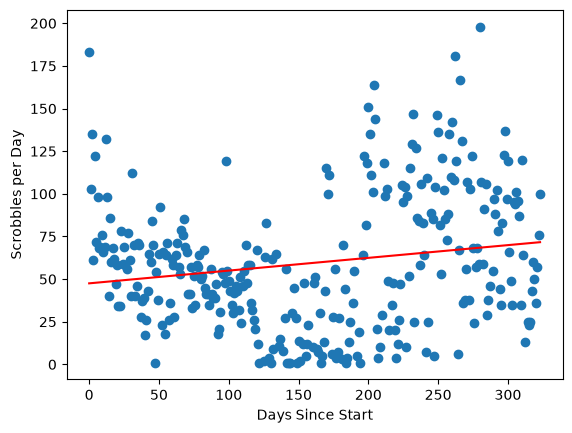

In [17]:
daily['days_since_start'] = (daily.index - daily.index[0]).days

X = daily[['days_since_start']]
y = daily['scrobble_count']

model = LinearRegression(fit_intercept=True)
model.fit(X, y)

xfit = np.linspace(X.min().iloc[0], X.max().iloc[0], 1000)
yfit = model.predict(xfit[:, np.newaxis])

plt.scatter(X, y)
plt.plot(xfit, yfit, color='red')
plt.xlabel('Days Since Start')
plt.ylabel('Scrobbles per Day')

Polynomial w/ a degree of 2 fits better

C:\Users\markl\pipx\venvs\jupyterlab\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


Text(0, 0.5, 'Scrobbles per Day')

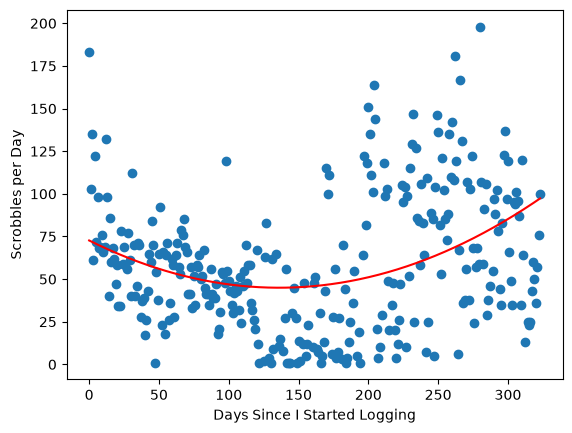

In [18]:
from sklearn.pipeline import make_pipeline

daily["days_since_start"] = (daily.index - daily.index[0]).days

X = daily[["days_since_start"]]
y = daily["scrobble_count"]

poly_model = make_pipeline(PolynomialFeatures(2), LinearRegression())

poly_model.fit(X, y)

xfit = np.linspace(X.min().iloc[0], X.max().iloc[0], 1000)
yfit = poly_model.predict(xfit[:, np.newaxis])

plt.scatter(X, y)  
plt.plot(xfit, yfit, color="red")
plt.xlabel("Days Since I Started Logging")
plt.ylabel("Scrobbles per Day")

Using the [unofficial docs](https://lastfm-docs.github.io/api-docs/user/getLovedTracks/#examples) once again, the data can be combined with the ```User.getLovedTracks``` header. A new boolean field called ```is_loved``` can be joined to the full scrobble dataset

In [19]:
all_loved_tracks = []
loved_page = 1
total_loved_pages = 1

while loved_page <= total_loved_pages:
    response = requests.get('http://ws.audioscrobbler.com/2.0/', params={
        'method': 'user.getlovedtracks',
        'user': USERNAME,
        'api_key': API_KEY,
        'format': 'json',
        'limit': 200,
        'page': loved_page
    })
    data = response.json()
    if loved_page == 1:
        total_loved_pages = int(data['lovedtracks']['@attr']['totalPages'])
    tracks = data['lovedtracks']['track']
    for track in tracks:
        all_loved_tracks.append({
            'artist': track['artist']['name'],
            'track': track['name'],
            'timestamp': int(track['date']['uts']) if 'date' in track else None
        })
    loved_page += 1

In [20]:
lovedScrobbles = pd.DataFrame(all_loved_tracks)
lovedScrobbles['is_loved'] = 1
lovedScrobbles = lovedScrobbles.drop_duplicates(subset=['artist', 'track'])

df_merged = pd.merge(
    scrobbles,
    lovedScrobbles[['artist', 'track', 'is_loved']],
    left_on=['artist', 'song'],
    right_on=['artist', 'track'],
    how='left'
)

loved = df_merged.drop(columns=['track'])
loved['is_loved'] = loved['is_loved'].fillna(0).astype(int)
loved

,artist,album,song,url,date,timestamp,date_only,month,is_loved
0,Portishead,Dummy,Biscuit,https://www.last.fm/music/Portishead/_/Biscuit,2026-10-07 19:49:00,1791402595,2026-10-07,2026-10,1
1,Portishead,Dummy,Pedestal,https://www.last.fm/music/Portishead/_/Pedestal,2026-10-07 19:44:00,1791402292,2026-10-07,2026-10,0
2,Portishead,Dummy,Roads,https://www.last.fm/music/Portishead/_/Roads,2026-10-07 19:41:00,1791402072,2026-10-07,2026-10,1
3,Portishead,Dummy,Numb,https://www.last.fm/music/Portishead/_/Numb,2026-10-07 19:36:00,1791401768,2026-10-07,2026-10,0
4,Portishead,Dummy,Wandering Star,https://www.last.fm/music/Portishead/_/Wanderi...,2026-10-07 19:32:00,1791401532,2026-10-07,2026-10,1
...,...,...,...,...,...,...,...,...,...
18084,Tame Impala,Lonerism,Why Won't They Talk to Me?,https://www.last.fm/music/Tame+Impala/_/Why+Wo...,2025-11-18 11:00:00,1763463648,2025-11-18,2025-11,1
18085,Portishead,Portishead,Over,https://www.last.fm/music/Portishead/_/Over,2025-11-18 10:56:00,1763463370,2025-11-18,2025-11,1
18086,Tame Impala,Deadbeat,Obsolete,https://www.last.fm/music/Tame+Impala/_/Obsolete,2025-11-18 10:47:00,1763462844,2025-11-18,2025-11,1
18087,Tame Impala,Deadbeat,Piece Of Heaven,https://www.last.fm/music/Tame+Impala/_/Piece+...,2025-11-18 10:42:00,1763462559,2025-11-18,2025-11,0
